# Task 4 (Level 2 — Intermediate): Decision Trees & Cost-Complexity Pruning on Iris

Compares an unrestricted CART classifier (`Depth=5, Leaves=8`) against cost-complexity pruned trees tuned strictly on the 120-row training split.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
m4 = json.loads((ROOT / 'results/metrics/task4_decision_tree_metrics.json').read_text())
ccp_df = pd.read_csv(ROOT / 'results/tables/task4_decision_tree_ccp_path.csv')
print('Unrestricted Tree -> Depth:', m4['unrestricted_tree']['depth'], 'Leaves:', m4['unrestricted_tree']['n_leaves'], 'Test Macro-F1:', round(m4['unrestricted_tree']['test_metrics']['f1_macro'], 4))
print('Pruned Tree       -> Depth:', m4['selected_pruned_tree']['fitted_depth'], 'Leaves:', m4['selected_pruned_tree']['fitted_n_leaves'], 'Test Macro-F1:', round(m4['selected_pruned_tree']['test_metrics']['f1_macro'], 4))
print('\nLearned Human-Readable Rules:\n' + m4['selected_pruned_tree']['decision_rules_text'])
display(ccp_df)

Unrestricted Tree -> Depth: 5 Leaves: 8 Test Macro-F1: 0.9333
Pruned Tree       -> Depth: 3 Leaves: 4 Test Macro-F1: 0.9666

Learned Human-Readable Rules:
|--- petal_length <= 2.45
|   |--- class: 0
|--- petal_length >  2.45
|   |--- petal_width <= 1.65
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal_length >  4.95
|   |   |   |--- class: 2
|   |--- petal_width >  1.65
|   |   |--- class: 2



,ccp_alpha,depth,n_leaves,train_f1_macro,cv_f1_macro_mean,cv_f1_macro_std
0,0.000000,5,8,1.000000,0.949605,0.019152
1,0.006250,4,6,0.991665,0.949605,0.019152
2,0.008114,4,6,0.991665,0.957971,0.029932
3,0.033929,2,3,0.966646,0.932739,0.023222


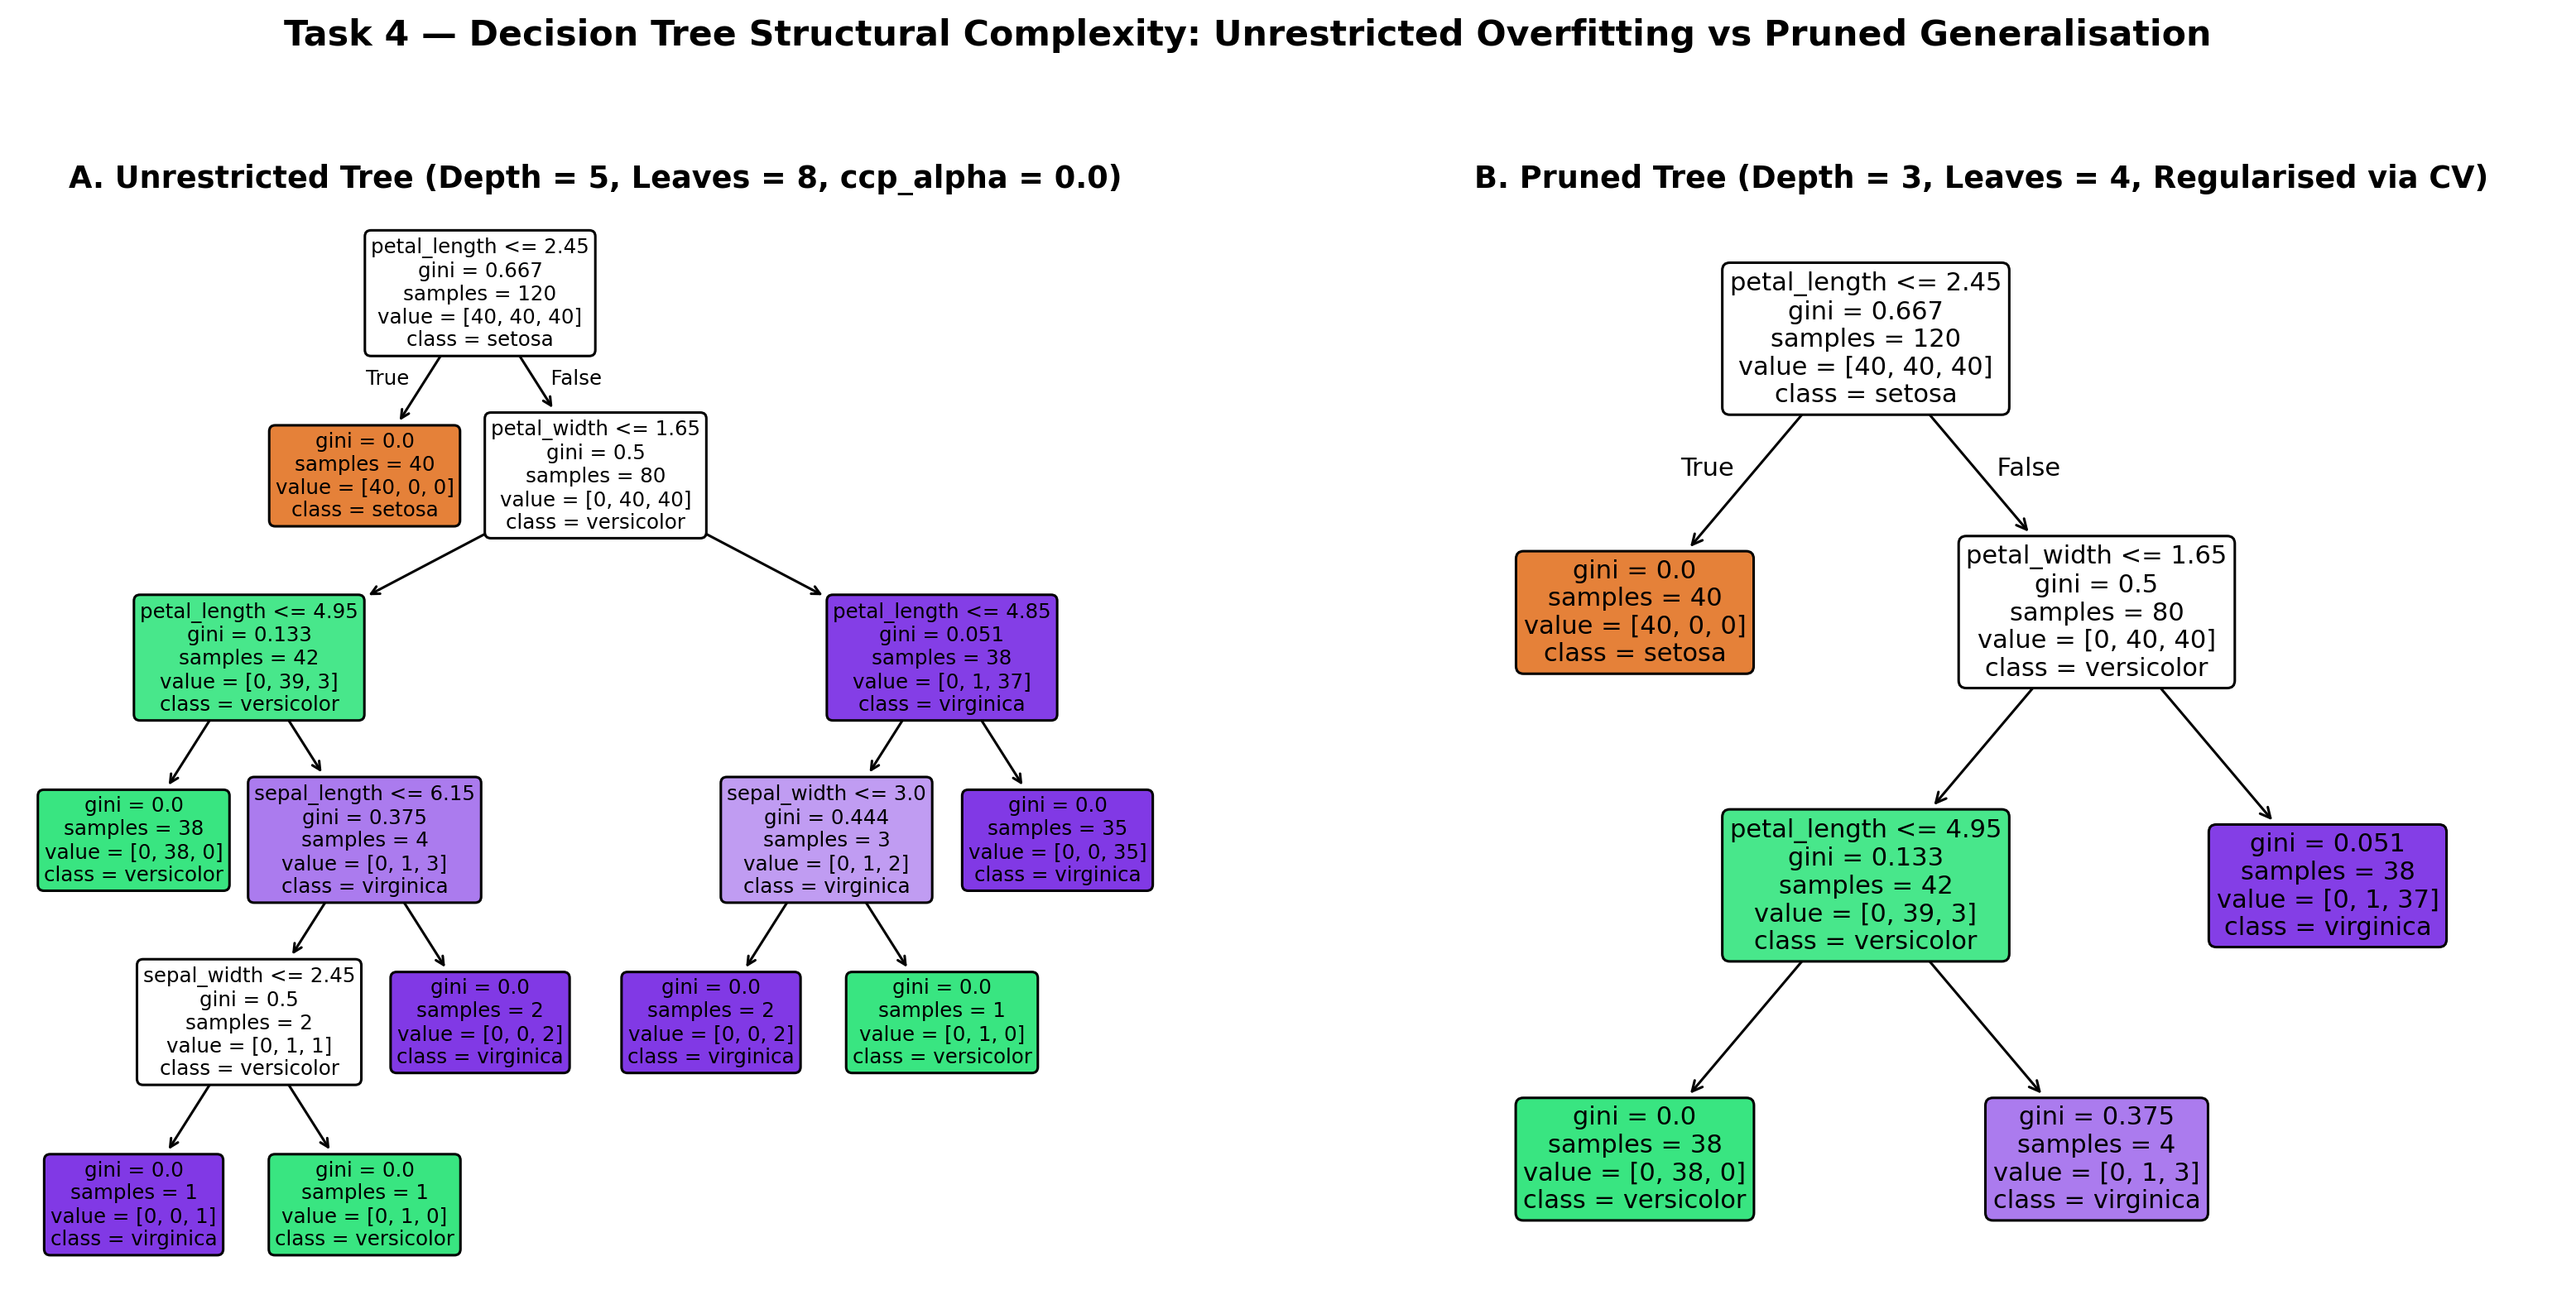

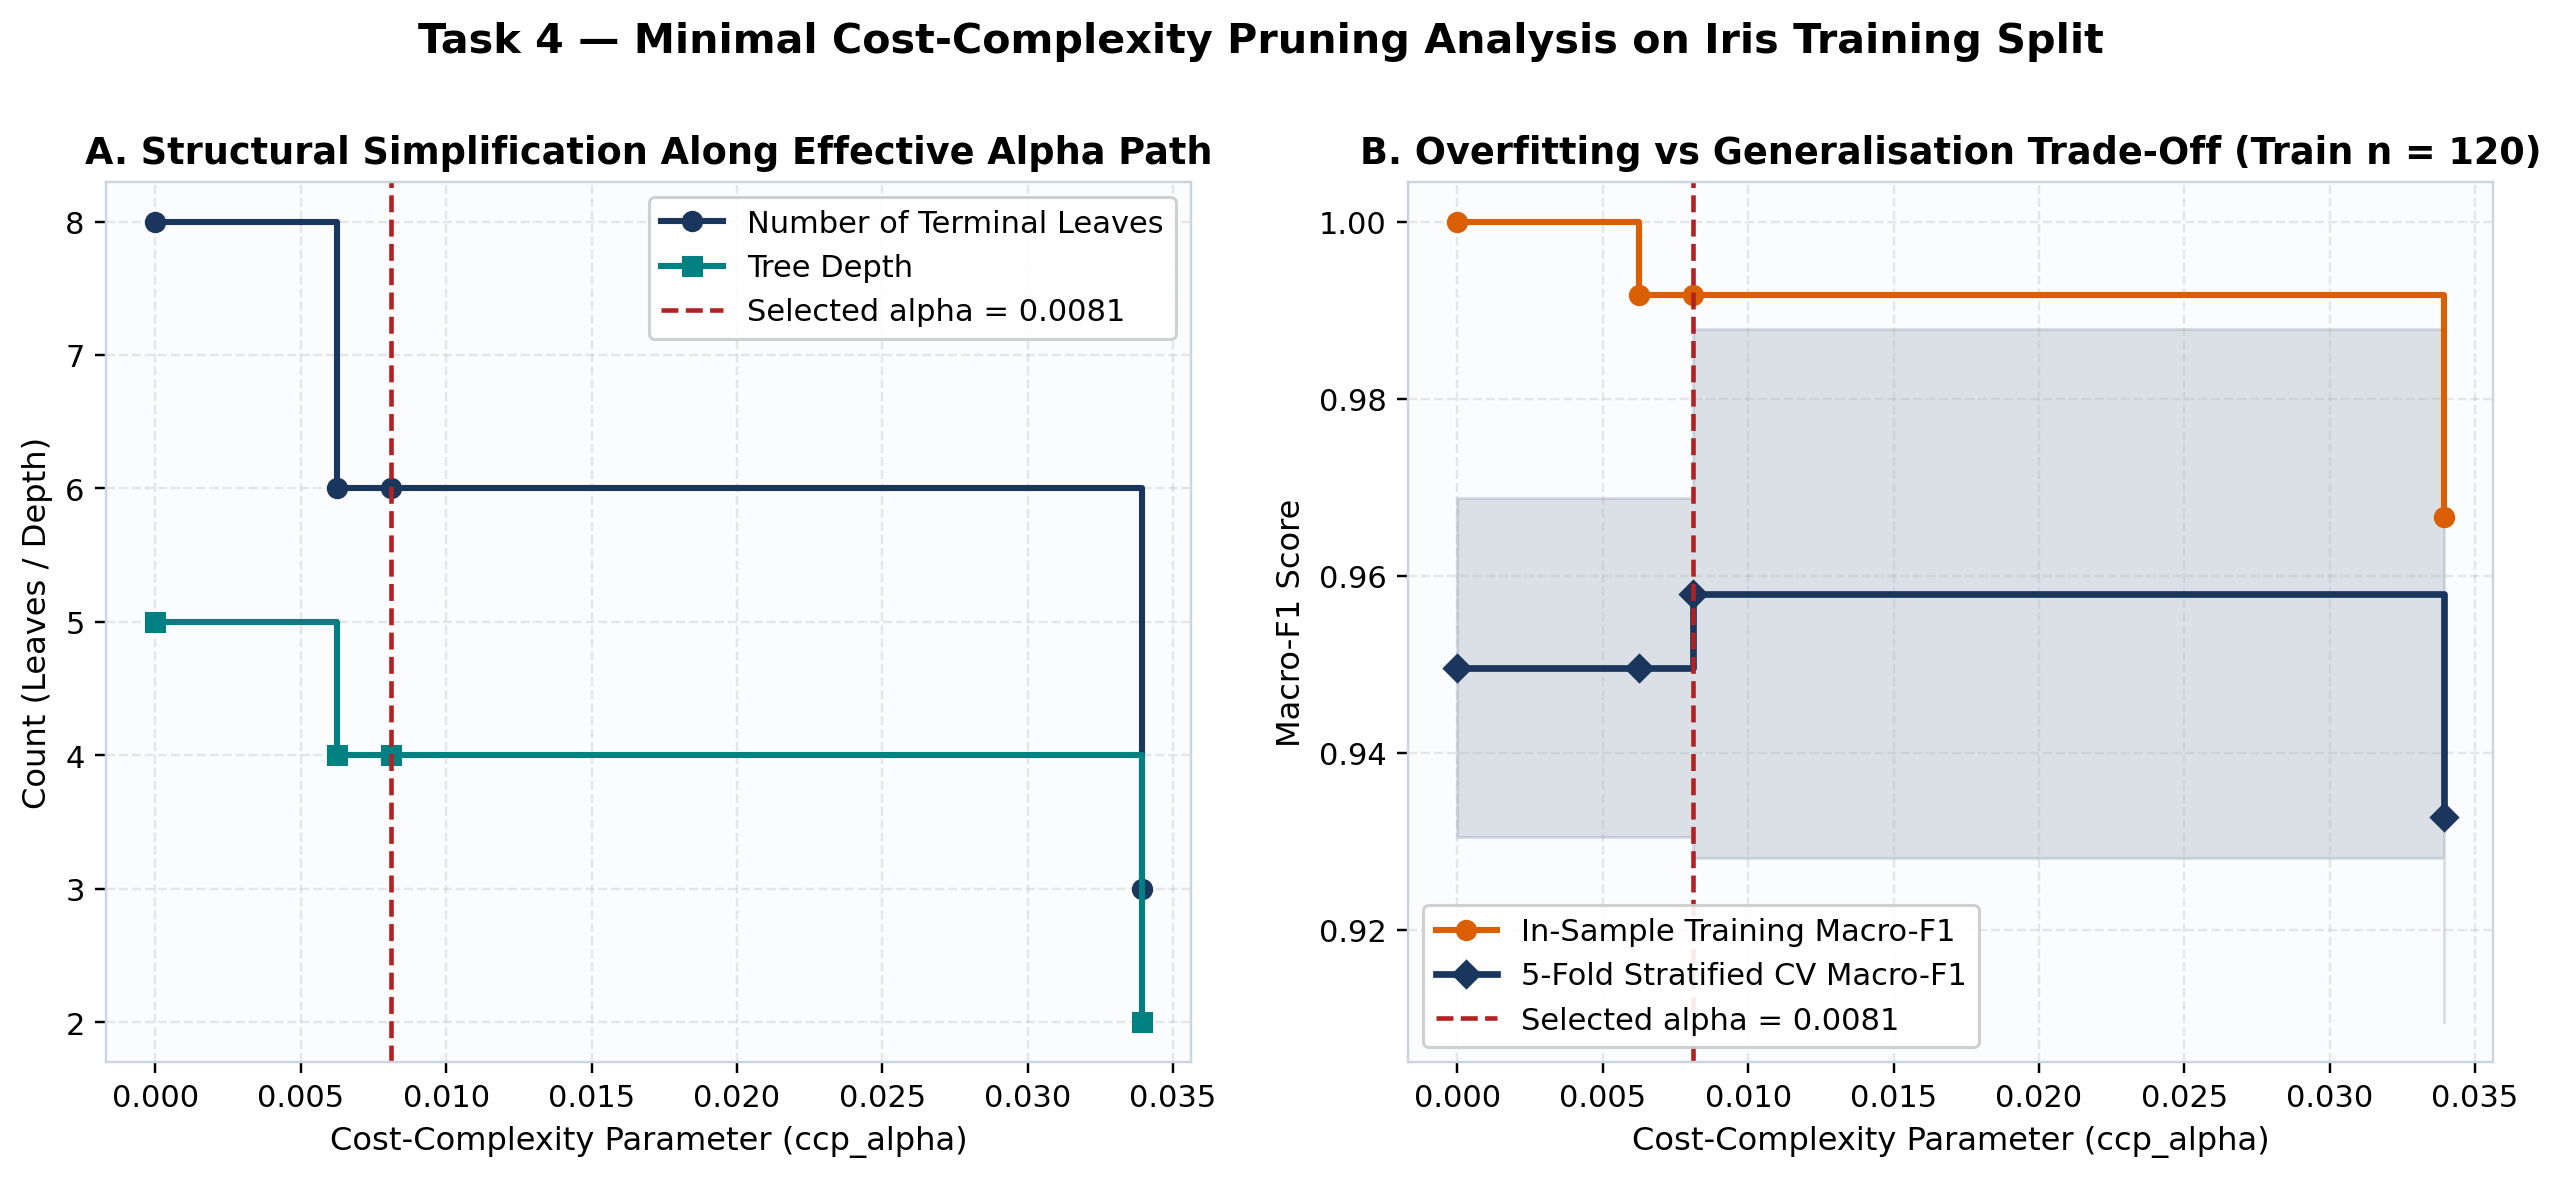

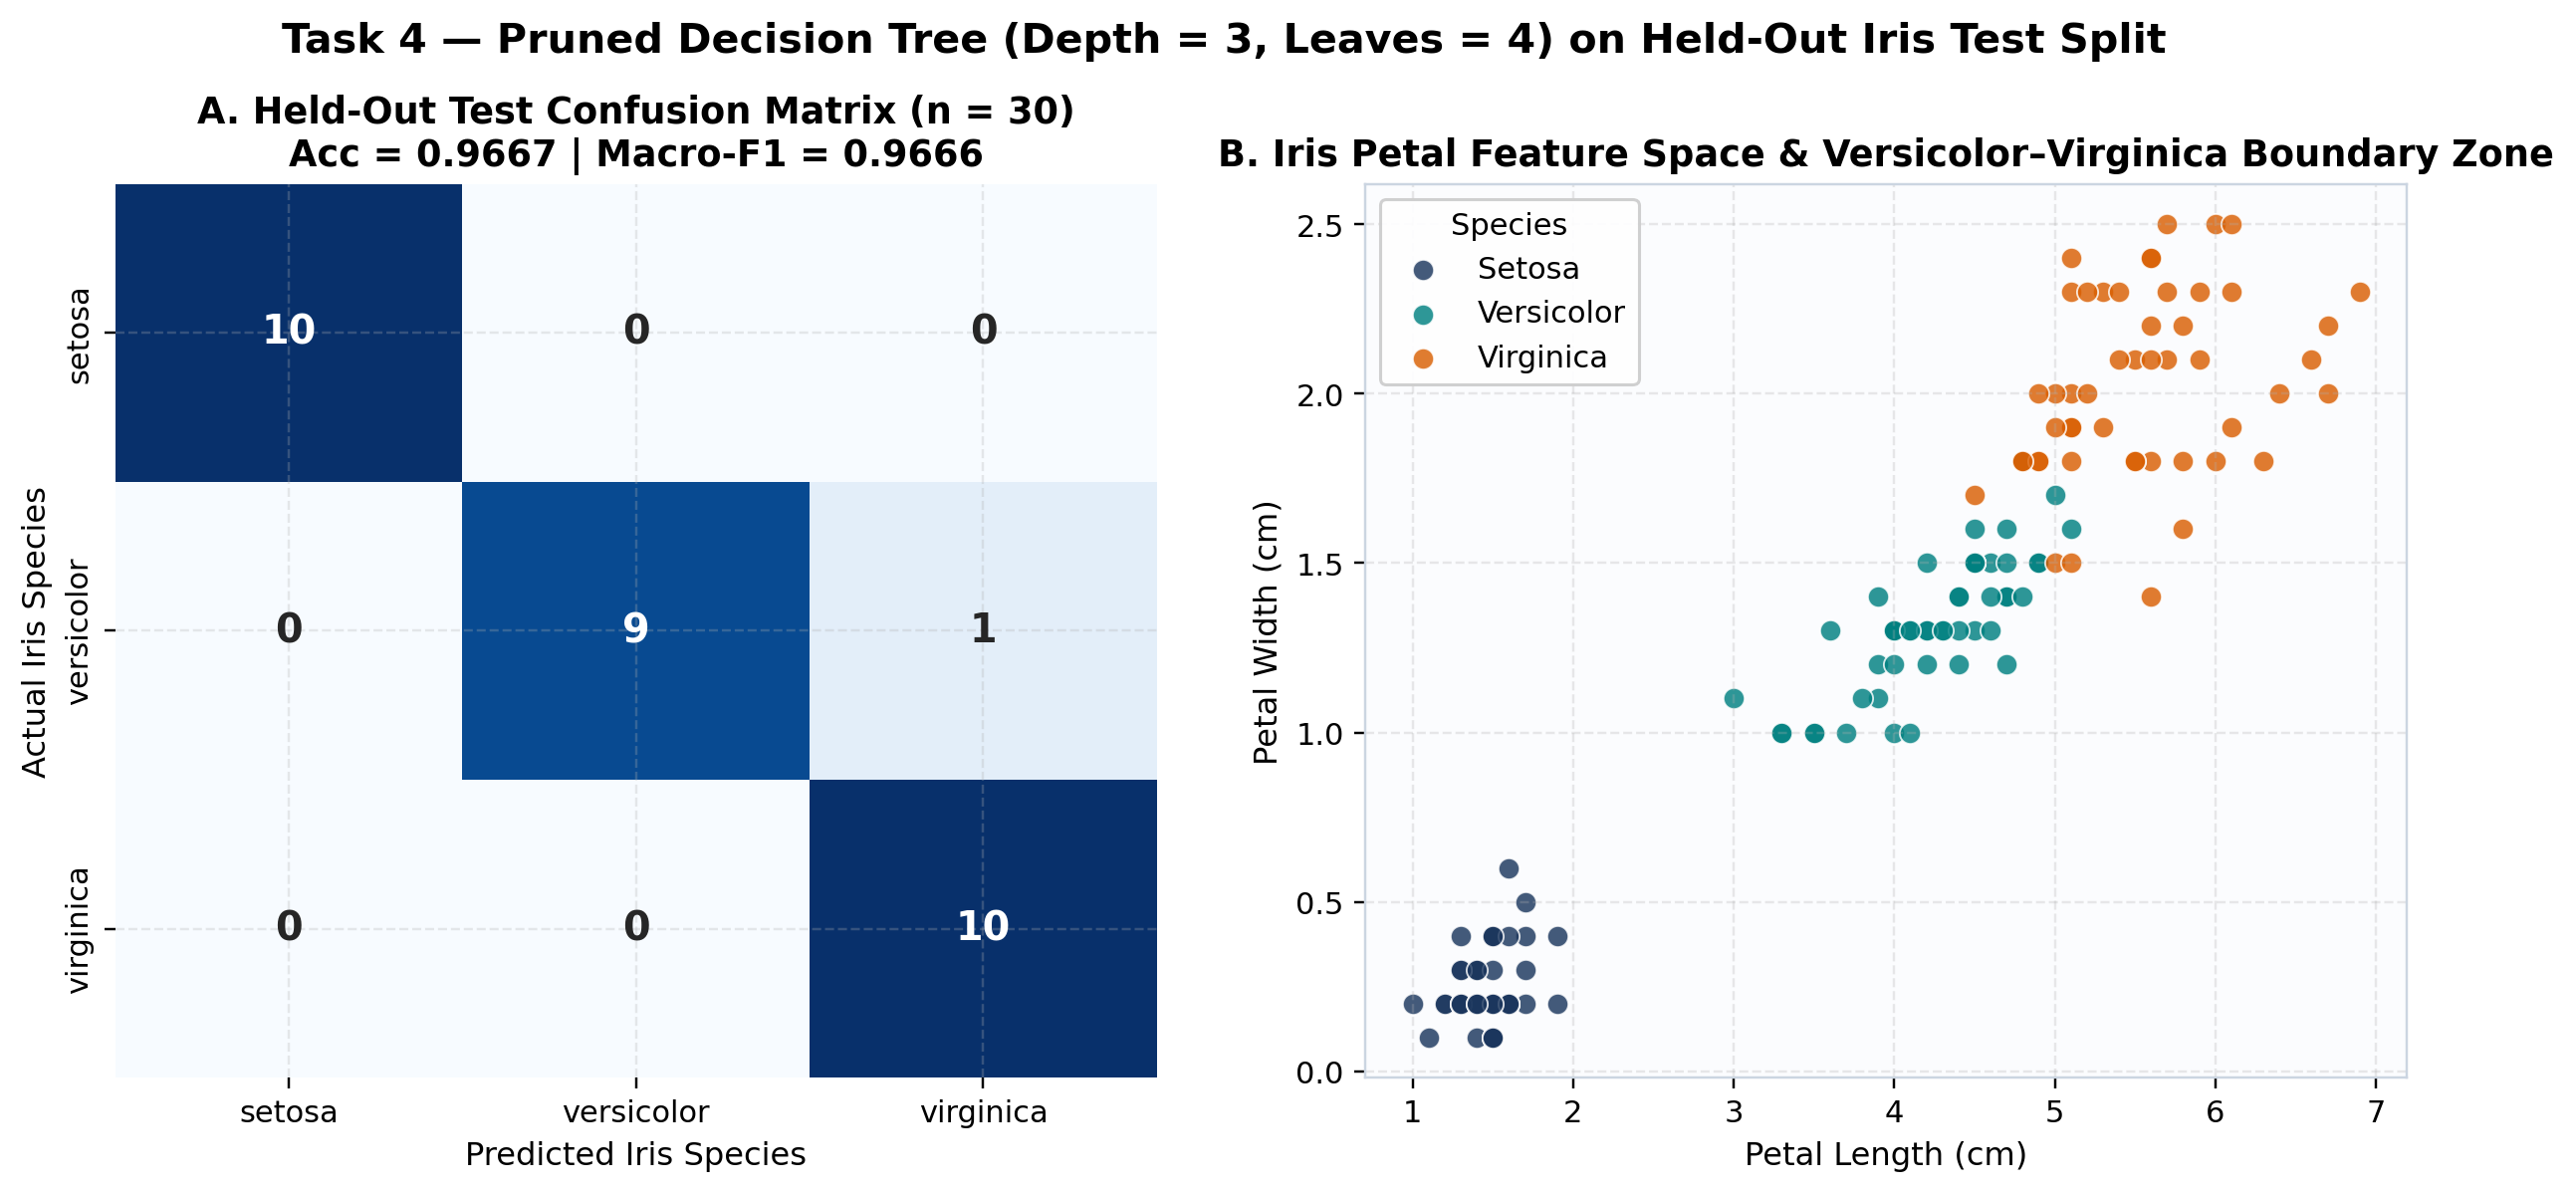

In [2]:
display(Image(filename=str(ROOT / 'results/figures/fig08_decision_tree_unrestricted_vs_pruned.png')))
display(Image(filename=str(ROOT / 'results/figures/fig09_decision_tree_ccp_pruning_curve.png')))
display(Image(filename=str(ROOT / 'results/figures/fig10_decision_tree_confusion_matrix.png')))